# Transformer Example: Damage Detection from Vibration Records

**Background**<br>
Pumps, blowers and motors run water utilities and building plants. A growing bearing fault changes the machine's vibration signature long before failure. An accelerometer can hear it, and a classifier can learn it. Instead of stepping through the signal like an RNN, a Transformer's self-attention lets every time step look at every other step at once and decide which moments matter.

**Dataset**<br>
2000 acceleration windows from a real rotating-machine test rig: the public Case Western Reserve University Bearing Data Center dataset, the standard benchmark in mechanical/structural health monitoring. Each window is 100 samples recorded at 2 kHz (0.05 s of vibration, decimated from the original 12 kHz record, z-scored). Classes: 1000 healthy windows vs 1000 windows with an inner-race bearing fault (fault sizes 0.007–0.028 inch). A fault acts like a tiny hammer blow inside the machine. Once per bearing rotation it strikes the raceway, producing a repetitive impulse pattern.

Case Western Reserve University *Bearing Data Center* (K. A. Loparo), drive-end accelerometer, 12 kHz sampling, motor load 0 hp: files 97–100 (normal) and 105–108 (inner-race fault). 

## The training loop

A training loop usually goes through the following five steps:

```python
optimizer.zero_grad()       # 1. forget the gradients from the previous step
y_hat  = model(x)           # 2. forward pass: make a prediction
loss   = loss_fn(y_hat, y)  # 3. measure how wrong we are
loss.backward()             # 4. backpropagation: compute gradients
optimizer.step()            # 5. update the weights a little
```

Only three things change between architectures: 
- the data
- the model (`nn.Module`) 
- the loss function

## Transformer Model

Two pieces of new machinery (beyond Example 2's CNN):
1. **Token embedding** — a `Linear(1, 32)` turns each acceleration sample into a 32-dim vector (a "word embedding" for numbers).
2. **Positional encoding** — attention has *no built-in sense of order*, so we add a fixed sinusoidal "position stamp" to every time step.

`nn.TransformerEncoderLayer(d_model=32, nhead=4)` runs 4 attention heads, each free to look for a different pattern. After the encoder, we average the 100 output vectors and classify with one `Linear` layer + `Sigmoid` — so `model(x)` directly returns p(fault).

In [1]:
import torch                        # PyTorch: tensors + autograd
import torch.nn as nn               # neural-network building blocks (layers, losses)
from torch.utils.data import TensorDataset, DataLoader   # pairs samples, yields mini-batches
import numpy as np                  # read the .npz data file
import matplotlib.pyplot as plt     # plotting

torch.manual_seed(355)              # reproducibility: same "random" numbers every run
print("PyTorch version:", torch.__version__)

PyTorch version: 2.12.1


### 1. Load the vibration records and look at them

The `.npz` file holds 2000 windows of 100 samples each, plus labels (0 = healthy, 1 = fault). As always: **shuffle before splitting**. The two traces below contrast a healthy window (broadband noise) with a faulty one (sharp, periodically repeated impulse spikes — each strike of the damaged raceway).

In [2]:
d = np.load("Data/vibration_windows.npz")
X = torch.tensor(d["X"]).unsqueeze(-1)            # (2000, 100) -> (2000, 100, 1): (batch, time, features)
y = torch.tensor(d["y"]).unsqueeze(1).float()     # (2000, 1), 1.0 = fault
print("X:", X.shape, " healthy:", int((y == 0).sum()), " fault:", int((y == 1).sum()))

perm0 = torch.randperm(len(X))                    # random permutation of indices 0..1999
X, y = X[perm0], y[perm0]                         # shuffle! (the file groups classes together)
split = int(0.8 * len(X))                         # boundary for the 80/20 split
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X: torch.Size([2000, 100, 1])  healthy: 1000  fault: 1000


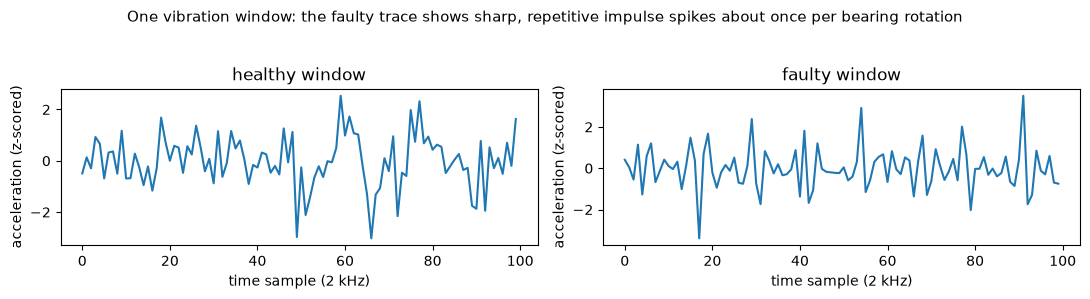

In [3]:
# one healthy and one faulty window: the fault shows sharp repetitive impulses
# .nonzero()[0] is a 1-element index TENSOR -> X[[i]] keeps the batch dim (1, 100, 1).
# .item() turns it into a plain int, so X[i] is one window of shape (100, 1).
i_healthy = (y.squeeze() == 0).nonzero()[0].item()   # first healthy window
i_fault   = (y.squeeze() == 1).nonzero()[0].item()   # first faulty window

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(X[i_healthy][:, 0]); axes[0].set_title("healthy window")
axes[1].plot(X[i_fault][:, 0]);   axes[1].set_title("faulty window")
for ax in axes:
    ax.set_xlabel("time sample (2 kHz)")
    ax.set_ylabel("acceleration (z-scored)")
fig.suptitle("One vibration window: the faulty trace shows sharp, repetitive impulse "
             "spikes about once per bearing rotation", fontsize=11)
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

### 2. Build the Transformer model

The positional encoding below is the classic sinusoidal recipe: each of the 100 time steps gets a unique "stamp" made of sines and cosines of different frequencies. `register_buffer` stores it in the model **without training it**.

In [ ]:
class VibrationTransformer(nn.Module):   # every PyTorch model subclasses nn.Module
    def __init__(self, d_model=32, nhead=4):
        super().__init__()               # required: initialize the base class
        self.embed = nn.Linear(1, d_model)   # each sample (1 number) -> 32-dim token
        self.pos_emb = nn.Parameter(torch.zeros(100, d_model)) # learned positional embedding: one 32-dim vector per time step, learned from data
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,      # 32-dim tokens, 4 attention heads
            dim_feedforward=64,                # small feed-forward block inside each layer
            batch_first=True, dropout=0.0)     # input (batch, time, features)
        self.encoder = nn.TransformerEncoder(layer, num_layers=1)  # stack 1 layer of self-attention + feed-forward
        self.head = nn.Sequential(
            nn.Linear(d_model, 1),             # average of 100 token vectors -> 1 score
            nn.Sigmoid(),                      # squashes the score -> probability in (0, 1)
        )

    def forward(self, x):            # how data flows; model(x) calls this automatically
        h = self.embed(x) + self.pos_emb  # token value + position stamp
        h = self.encoder(h)          # every time step attends to every other
        return self.head(h.mean(dim=1))   # average all time steps -> p(fault)

model = VibrationTransformer()       # build the network (weights start random)
loss_fn   = nn.BCELoss()             # binary cross-entropy; expects probabilities in (0, 1)
optimizer = torch.optim.Adam(model.parameters(), lr=0.002)  # updates all weights; lr = step size

### 3. Train with mini-batches

`TensorDataset` pairs each window with its label; the `DataLoader` shuffles the training set every epoch and slices it into **mini-batches of 64**, yielded one at a time as `(xb, yb)`. Inside the batch loop you still write the universal five-line training loop yourself.

In [5]:
train_ds = TensorDataset(X_train, y_train)      # pairs each window with its label
train_loader = DataLoader(train_ds, batch_size=64,
                          shuffle=True)         # yields shuffled (xb, yb) batches of 64

for epoch in range(30):                         # 1 epoch = one full pass over the training data
    model.train()                               # training mode (affects layers like dropout)
    total = 0.0
    for xb, yb in train_loader:                 # DataLoader shuffles + slices mini-batches for us
        optimizer.zero_grad()                   # gradients accumulate -> erase the previous step's
        out = model(xb)                         # forward pass: p(fault) for the batch
        loss = loss_fn(out, yb)                 # scalar: how wrong the batch is
        loss.backward()                         # backprop: dLoss/dWeight for EVERY weight (autograd)
        optimizer.step()                        # update all weights a small step downhill
        total += loss.item() * len(xb)          # .item() -> Python float; x batch size = fair average
    model.eval()                                # evaluation mode
    with torch.no_grad():                       # no gradients needed for testing (faster)
        acc = ((model(X_test) > 0.5).float() == y_test).float().mean()  # p>0.5 <=> "fault"; mean = accuracy
    print(f"epoch {epoch+1:2d} | train loss {total/len(train_ds):.4f} | test acc {acc:.1%}")

epoch  1 | train loss 0.6902 | test acc 48.2%
epoch  2 | train loss 0.4947 | test acc 92.5%
epoch  3 | train loss 0.1500 | test acc 94.5%
epoch  4 | train loss 0.1092 | test acc 92.8%
epoch  5 | train loss 0.1138 | test acc 93.8%
epoch  6 | train loss 0.1466 | test acc 95.2%
epoch  7 | train loss 0.1173 | test acc 94.7%
epoch  8 | train loss 0.0907 | test acc 95.2%
epoch  9 | train loss 0.0799 | test acc 94.5%
epoch 10 | train loss 0.0751 | test acc 93.8%
epoch 11 | train loss 0.0858 | test acc 95.0%
epoch 12 | train loss 0.0695 | test acc 95.2%
epoch 13 | train loss 0.0629 | test acc 94.5%
epoch 14 | train loss 0.0607 | test acc 95.0%
epoch 15 | train loss 0.0721 | test acc 94.5%
epoch 16 | train loss 0.0562 | test acc 95.2%
epoch 17 | train loss 0.0628 | test acc 93.3%
epoch 18 | train loss 0.0786 | test acc 93.3%
epoch 19 | train loss 0.0463 | test acc 94.7%
epoch 20 | train loss 0.0509 | test acc 93.0%
epoch 21 | train loss 0.0436 | test acc 94.5%
epoch 22 | train loss 0.0365 | tes

### 4. Test with a confusion matrix

On real data, accuracy alone hides *which* errors occur. A missed fault (false negative) is far more dangerous in structural health monitoring than a false alarm, so we always inspect the confusion matrix.

In [ ]:
model.eval()                          # inference mode
with torch.no_grad():                 # no gradients during testing
    p = model(X_test).squeeze()       # one p(fault) per test window; (400,1) -> (400,)
pred  = (p > 0.5).long()              # threshold the probability at 0.5
truth = y_test.squeeze().long()       # true labels

cm = torch.zeros(2, 2, dtype=torch.int64)     # confusion matrix: cm[true, predicted]
for t, pr in zip(truth, pred): # loop over true and predicted labels
    cm[t, pr] += 1 # increment the appropriate cell in the confusion matrix
print("            predicted intact  fault")
print(f"true intact      {cm[0,0]:5d}      {cm[0,1]:4d}")
print(f"true fault       {cm[1,0]:5d}      {cm[1,1]:4d}")
print(f"\nfalse alarms: {cm[0,1].item()} | missed faults: {cm[1,0].item()}")

            predicted intact  fault
true intact        199         8
true fault          12       181

false alarms: 8 | missed faults: 12


**Check** <br>
The fault files mix four severity levels (0.007″ to 0.028″). The smallest fault is close to healthy — did the model miss mostly those, or spread errors evenly? (Re-run with labels restricted to the two mildest faults for a harder, more realistic task.)

**Exercises**
1. Retrain using only fault size 0.021″ and 0.028″ vs healthy, then test on **0.007″**. Does the model detect damage it never saw at that severity? (This is why SHM papers report *generalization to unseen severity*.)
2. Compare against the RNN applied to the same windows (add a small head). Which architecture wins, and at what training cost?
3. The windows are z-scored, so absolute amplitude is lost. Is that good or bad for detecting early damage?
